In [1]:
import random
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
import math


def chrtomat(chr,n):
  mat = np.zeros((n, n), dtype=int)
  k=0
  for i in range(0,n):
    for j in range(i+1, n):
      mat[i][j] = chr[k]
      k+=1
  return mat


def is_single_chain(matrix, n):
    adjacency_list = {i: [] for i in range(n)}
    for i in range(n):
        for j in range(i + 1, n):
            if matrix[i][j] > 0:  # Bond exists
                adjacency_list[i].append(j)
                adjacency_list[j].append(i)

    # Perform BFS or DFS to check connectivity
    visited = [False] * n

    def dfs(node):
        visited[node] = True
        for neighbor in adjacency_list[node]:
            if not visited[neighbor]:
                dfs(neighbor)

    # Start DFS from the first node
    dfs(0)

    # Check if all nodes are visited
    return all(visited)


def mattochr(matrix,n):
  chr = []
  for i in range(0,n):
        for j in range(i+1, n):
          chr.append(matrix[i][j])
  return chr


def reduce_row_or_col_randomly(mat, i, n):
  rowi = [(i, j) for j in range(i + 1, n)]
  coli = [(j, i) for j in range(0, i)]
  ind = rowi + coli
  random.shuffle(ind)
  for j in ind:
    if mat[j[0]][j[1]] > 0:
      mat[j[0]][j[1]] -= 1
      return True
  return False


def increase_row_or_col_randomly(mat, i, n):
  rowi = [(i, j) for j in range(i + 1, n)]
  coli = [(j, i) for j in range(0, i)]
  ind = rowi + coli
  random.shuffle(ind)
  for j in ind:
    if (np.sum(mat[j[0]]) + np.sum(mat[:, j[0]]))<4 and (np.sum(mat[j[1]]) + np.sum(mat[:, j[1]]))<4:
      mat[j[0]][j[1]] += 1
      return True
  return False


def adjmat(mat,n):
  for i in range(0,n):
    sum1 = np.sum(mat[i]) + np.sum(mat[:, i])
    while sum1 > 4:
      if not reduce_row_or_col_randomly(mat, i, n):
        break
      sum1 = np.sum(mat[i]) + np.sum(mat[:, i])
    while sum1 == 0:
      if not increase_row_or_col_randomly(mat, i, n):
        break
      sum1 = np.sum(mat[i]) + np.sum(mat[:, i])
  return mat


def create_matrix(n):
  matrix = np.zeros((n, n), dtype=int)
  indices = [(i, j) for i in range(n) for j in range(i + 1, n)]
  random.shuffle(indices)
  for i in indices:
      sum1 = np.sum(matrix[i[0]]) + np.sum(matrix[:, i[0]])
      sum2 = np.sum(matrix[i[1]]) + np.sum(matrix[:, i[1]])
      max = min(3, 4-sum1, 4-sum2)
      if sum1 < 4 and sum2 < 4:
        bond = random.randint(0, max)
        matrix[i[0]][i[1]] = bond
  matrix = adjmat(matrix,n)
  return matrix


def generate_coordinate(matrix):
    n = len(matrix)

    # Bond lengths for different bond types
    bond_lengths = {1: 1.54, 2: 1.34, 3: 1.20}
    min_non_bond_distance = 2.0

    # Generate random 3D coordinates for n carbon atoms
    coordinates = np.random.rand(n, 3) * n  # Scale coordinates for better visibility

    # Adjust distances iteratively for bonding and non-bonding atoms
    for iteration in range(100):  # Limit iterations to prevent infinite loops
        adjustments_made = False
        for i in range(n):
            for j in range(i + 1, n):
                vector = coordinates[j] - coordinates[i]
                current_distance = math.sqrt((coordinates[j][0]-coordinates[i][0])**2+(coordinates[j][1]-coordinates[i][1])**2+(coordinates[j][2]-coordinates[i][2])**2)
                bond_order = matrix[i][j]

                if bond_order > 0:  # Bonded atoms
                    desired_distance = bond_lengths[bond_order]
                else:  # Non-bonded atoms
                    desired_distance = max(current_distance, min_non_bond_distance)

                # Adjust if the current distance is not as desired
                if not np.isclose(current_distance, desired_distance, atol=0.05):
                    scale = desired_distance / current_distance
                    midpoint = (coordinates[i] + coordinates[j]) / 2
                    # Move each atom halfway to maintain balance
                    coordinates[i] = midpoint + (coordinates[i] - midpoint) * scale
                    coordinates[j] = midpoint + (coordinates[j] - midpoint) * scale
                    adjustments_made = True

        if not adjustments_made:
            break  # Stop if no adjustments are needed

    return coordinates


def plot_structure(coordinates, matrix, n, ax):

    #fig = plt.figure()
    #ax = fig.add_subplot(111, projection='3d')

    bond_colors = {1: 'black', 2: 'blue', 3: 'red'}

    for i, (x, y, z) in enumerate(coordinates):
        ax.scatter(x, y, z, color='gray', s=100, label='C' if i == 0 else "")

    for i in range(n):
        for j in range(i + 1, n):
            bond_order = matrix[i][j]
            if bond_order > 0:
                x_vals = [coordinates[i][0], coordinates[j][0]]
                y_vals = [coordinates[i][1], coordinates[j][1]]
                z_vals = [coordinates[i][2], coordinates[j][2]]
                ax.plot(x_vals, y_vals, z_vals, color=bond_colors[bond_order], linewidth=2)

    # Set labels and show plot
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    plt.legend()
    #plt.show()

def gen_dist_mat(coordinates,n):
  distance_matrix = np.zeros((n, n))
  for i in range(n):
    for j in range(i + 1, n):
      # Calculate Euclidean distance
      distance = math.sqrt((coordinates[j][0]-coordinates[i][0])**2+(coordinates[j][1]-coordinates[i][1])**2+(coordinates[j][2]-coordinates[i][2])**2)
      distance_matrix[i][j] = distance
  return distance_matrix

def calc_fitness(coordinates,chr,n):
  distance_matrix = gen_dist_mat(coordinates,n)
  fitness = 0
  for i in range(n):
    for j in range(i + 1, n):
      dist = distance_matrix[i][j]
      fitness+=4*0.065490*((3.4/dist)**12-(3.4/dist)**6)
  return fitness


"""
# Driver ccode
n = 5  # Number of carbon atoms
bond_matrix = create_matrix(n)

# Print the resulting matrix
print("Bond Matrix:")
for row in bond_matrix:
    print(row)
print(mattochr(bond_matrix,n))
# Plot the 3D structure
coordinates=generate_coordinate(bond_matrix)
plot_structure(coordinates, bond_matrix, n)

#print(coordinates)

distance_matrix = np.zeros((n, n))
for i in range(n):
  for j in range(i + 1, n):
    # Calculate Euclidean distance
    distance = np.linalg.norm(coordinates[i] - coordinates[j])
    distance_matrix[i][j] = distance
print(distance_matrix)
"""

'\n# Driver ccode\nn = 5  # Number of carbon atoms\nbond_matrix = create_matrix(n)\n\n# Print the resulting matrix\nprint("Bond Matrix:")\nfor row in bond_matrix:\n    print(row)\nprint(mattochr(bond_matrix,n))\n# Plot the 3D structure\ncoordinates=generate_coordinate(bond_matrix)\nplot_structure(coordinates, bond_matrix, n)\n\n#print(coordinates)\n\ndistance_matrix = np.zeros((n, n))\nfor i in range(n):\n  for j in range(i + 1, n):\n    # Calculate Euclidean distance\n    distance = np.linalg.norm(coordinates[i] - coordinates[j])\n    distance_matrix[i][j] = distance\nprint(distance_matrix)\n'

In [2]:
def crossover(chr1, chr2, n):
  m=len(chr1)
  i=random.randint(1, m-1)
  c1=[]
  c2=[]
  c1.extend(chr1[0:i])
  c1.extend(chr2[i:m])
  c2.extend(chr2[0:i])
  c2.extend(chr1[i:m])
  m1 =  chrtomat(c1,n)
  m2 =  chrtomat(c2,n)
  m1 = adjmat(m1,n)
  m2 = adjmat(m2,n)
  c1 = mattochr(m1,n)
  c2 = mattochr(m2,n)
  return c1, c2
#crossover([1, 0, 2, 1, 1, 0, 1, 1, 2, 0], [0, 1, 3, 0, 1, 1, 2, 0, 2, 0], 5)

In [3]:
def mutation(chr,n):
  m1 = chrtomat(chr,n)
  upper_triangle_indices = [(i, j) for i in range(n) for j in range(i + 1, n)]
  mut=False
  while not mut:
    rc = random.choice(upper_triangle_indices)
    i = random.randint(0,1)
    if i == 0:
      if m1[rc[0]][rc[1]] > 0:
        m1[rc[0]][rc[1]] -= 1
        adjmat(m1,n)
        mut=True
      else:
        if m1[rc[0]][rc[1]] < 3:
          m1[rc[0]][rc[1]] += 1
          adjmat(m1,n)
          mut=True
  return mattochr(m1,n)

#chr = mutation([1, 0, 2, 1, 1, 0, 1, 1, 2, 0], 5)
#print(chr)

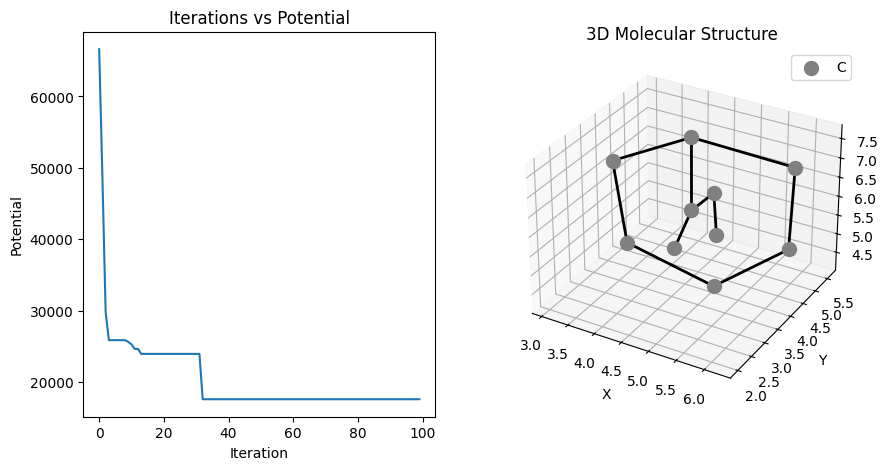

Potential = 17636.00832829349 kcal/mol


In [4]:
parent = []
children = []
combine = []
fitness = []
coordinate = []
iterfit = []
iter = 100 #no of iterations
popsize = 40 #population size
n = 10 #no of carbon
crossrate = 0.9 #crossover rate
mutrate = 0.3 #mutation rate
fitp = [0] * popsize
coop = [0] * popsize

count = 0
while count < popsize:
  mat = create_matrix(n)
  if is_single_chain(mat, n):
    chr = mattochr(mat,n)
    parent.append(chr)
    count+=1

for i in range(iter):
  count = 0
  for i in range(len(parent)):
    coordi = generate_coordinate(chrtomat(parent[i],n))
    fit = calc_fitness(coordi,parent[i],n)
    if fit < fitp[i] or fitp[i] == 0:
      fitp[i] = fit
      coop[i] = coordi
  while count < popsize:
    s1 = random.randint(0,len(parent)-1)
    s2 = random.randint(0,len(parent)-1)
    while s1 == s2:
      s2 = random.randint(0,len(parent)-1)
    if random.random() < crossrate:
      c1, c2 = crossover(parent[s1],parent[s2],n)
      if c1 not in children:
        m1 = chrtomat(c1,n)
        if is_single_chain(m1, n):
          children.append(c1)
          count+=1
      if c2 not in children:
        m2 = chrtomat(c2,n)
        if is_single_chain(m2, n):
          children.append(c2)
          count+=1 #create children population

  for i in children:
    if random.random() < mutrate:
      m1 = mutation(i,n)
      m11 = chrtomat(m1,n)
      if is_single_chain(m11, n):
        combine.append(m1)
        coordi = generate_coordinate(m11)
        fit = calc_fitness(coordi,m1,n)
        coordinate.append(coordi)
        fitness.append(fit)
      else:
        combine.append(i) #combine parent and children
        coordi = generate_coordinate(chrtomat(i,n))
        fit = calc_fitness(coordi,i,n)
        coordinate.append(coordi)
        fitness.append(fit)
    else:
      combine.append(i)
      coordi = generate_coordinate(chrtomat(i,n))
      fit = calc_fitness(coordi,i,n)
      coordinate.append(coordi)
      fitness.append(fit)

  combine.extend(parent)
  fitness.extend(fitp)
  coordinate.extend(coop)
  #print(len(combine),len(parent),len(children))


  for i in range(len(fitness)-1):
    swap = False
    for j in range(len(fitness)-i-1):
      if fitness[j] > fitness[j+1]:
        temp = fitness[j]
        fitness[j] = fitness[j+1]
        fitness[j+1] = temp
        temp = combine[j]
        combine[j] = combine[j+1]
        combine[j+1] = temp
        temp = coordinate[j]
        coordinate[j] = coordinate[j+1]
        coordinate[j+1] = temp
        swap = True
    if not swap:
      break #sort based on fitness

  parent = combine[:popsize]
  fitp = fitness[:popsize]
  coop = coordinate[:popsize]
  iterfit.append(fitness[0])
  children.clear()
  combine.clear()
  fitness.clear()
  coordinate.clear()


res = chrtomat(parent[0],n)
coordinates = coop[0]
fig = plt.figure(figsize=(10, 5))
ax1 = fig.add_subplot(121)
xaxis = list(range(len(iterfit)))
yaxis = iterfit
ax1.plot(xaxis,yaxis)
ax1.set_xlabel('Iteration')
ax1.set_ylabel('Potential')
ax1.set_title('Iterations vs Potential')
ax2 = fig.add_subplot(122, projection='3d')
plot_structure(coordinates, res, n, ax2)
ax2.set_title('3D Molecular Structure')
plt.show()
print("Potential =",fitp[0],"kcal/mol")

In [ ]:
import math
print(math.sqrt((7.53-7.54)**2+(12.44-10.73)**2+(12.23-12.21)**2))